# 17 — Results (draft of Section 5)

Every result below is read from the cached campaign and check files; nothing is simulated here. Prose is written as the paper's Results section. Exp. 1 locates the worst headings (5.2, 5.4); Exp. 2 sets the requirement at them (5.3); 5.6 checks both against independent simulations. Pending campaigns are listed at the end.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mvlse import fit_surrogate

sys.path.insert(0, str(Path.cwd().parent))
import common
import config

RES = Path.cwd().parent / "results" / "exp1_heading"
run = json.loads((RES / "campaign" / "run.json").read_text())
bracket = json.loads((RES / "bracket" / "run.json").read_text())
train = [json.loads(l) for l in (RES / "campaign" / "store.jsonl").read_text().splitlines() if l.strip()]
space = config.space_of(config.EXPERIMENTS["exp1_heading"]["space"])
TAU, N = config.TAU, config.N_ENCOUNTERS
w = space.encode([r["point"] for r in train])
y = np.array([r["y"] for r in train])
model = fit_surrogate(config.LSE["method"], space, w, y, correlation=config.LSE["correlation"],
                      rng=np.random.default_rng(config.SEED), n_starts=12)
levels = {n: space.variable(n).levels for n in space.discrete_names}
kt = lambda v: f"{v / config.KT:.0f} kt"
TWO = ListedColormap(["tab:red", "tab:green"])                      # outside, inside the level set

# Predictions on a grid: 41 x 41 (reception, range) per category, 37 headings.
N_P, N_R, N_PSI = 41, 41, 37
pu, ru, su = np.linspace(0, 1, N_P), np.linspace(0, 1, N_R), np.linspace(0, 1, N_PSI)
phys = {n: space.variable(n).from_unit(a) for n, a in zip(space.continuous_names, (pu, ru, su))}
G = np.stack(np.meshgrid(pu, ru, su, indexing="ij"), -1).reshape(-1, 3)
MU, S = {}, {}
for cat in space.categories:
    m, s = model.predict(np.column_stack([G, np.tile(np.array(cat, float), (len(G), 1))]))
    MU[cat], S[cat] = m.reshape(N_P, N_R, N_PSI), s.reshape(N_P, N_R, N_PSI)
print(f"exp1: {len(y)} samples, {run['outcome']['n_initial']} initial; {len(MU)} categories predicted")

# Exp. 2: the requirement surfaces at the two regime extremes.
P2 = config.EXPERIMENTS["exp2_surface"]
space2 = config.space_of(P2["space"])
RES2 = Path.cwd().parent / "results" / "exp2_surface"
EXP2 = {}
for dpsi in P2["headings"]:
    st = [json.loads(l) for l in (RES2 / f"dpsi{dpsi:.0f}_campaign" / "store.jsonl").read_text().splitlines() if l.strip()]
    w2 = space2.encode([r["point"] for r in st]); y2 = np.array([r["y"] for r in st])
    EXP2[dpsi] = {"run": json.loads((RES2 / f"dpsi{dpsi:.0f}_campaign" / "run.json").read_text()),
                  "bracket": json.loads((RES2 / f"dpsi{dpsi:.0f}_bracket" / "run.json").read_text()),
                  "w": w2, "y": y2, "speed": P2["speed_at"][dpsi],
                  "model": fit_surrogate(config.LSE["method"], space2, w2, y2, correlation=config.LSE["correlation"],
                                         rng=np.random.default_rng(config.SEED), n_starts=12)}
print("exp2:", ", ".join(f"{d:.0f} deg at {kt(v['speed'])}: {len(v['y'])} samples" for d, v in EXP2.items()))

exp1: 250 samples, 36 initial; 36 categories predicted


exp2: 2 deg at 20 kt: 250 samples, 180 deg at 60 kt: 250 samples


## 5.1 Simulation setup and bracket checks

Two campaigns, each limited to 250 samples, every response estimated from $10^5$ encounters:
- **Exp. 1** (six variables: the four CNS variables, relative heading 2–180° and speed class) locates the worst headings. It started from 36 initial samples, one per category, and took 6.0 h on 100 parallel workers.
- **Exp. 2** (the four CNS variables) sets the requirement at the two worst headings that Exp. 1 found (Section 5.2): 2° at 20 kt and 180° at 60 kt. Each run started from 24 initial samples, two per category, and took 3.5 h and 4.7 h.

Bracket checks confirmed that every design space contains the boundary.
- **Best CNS** (reception probability 1, 15 km, 3 m, 1 m/s): no LoS in $10^5$ encounters at any heading and speed checked.
- **Worst CNS** (0.1, 300 m, 92.6 m, 10 m/s): $P(\mathrm{LoS})$ of 0.38 (2°, 20 kt) to 1.

Of Exp. 1's samples, 125 were acceptable and 125 not, and 44 (18%) had no LoS.

In [2]:
# Bracket check and campaign facts.
rows = [{"speed class": kt(c["point"]["speed"]), "heading [deg]": c["point"]["dpsi"],
         "CNS": "best" if c["point"]["p_reception"] == 1.0 else "worst",
         "P(LoS)": common.show_p(c["y"]), "acceptable": c["acceptable"]} for c in bracket["outcome"]["corners"]]
display(pd.DataFrame(rows))
zero = np.sum(y <= np.log10(0.5 / (N + 1)) + 1e-9)
print(f"campaign: {len(y)} samples at {N:.0e} encounters each, {run['outcome']['seconds'] / 3600:.1f} h on "
      f"{run['shared']['N_JOBS']} workers; {zero} samples ({zero / len(y):.0%}) with no LoS; "
      f"{np.sum(y <= TAU)} acceptable, {np.sum(y > TAU)} not")
for d, v in EXP2.items():
    for c in v["bracket"]["outcome"]["corners"]:
        print(f"exp2 bracket {d:.0f} deg, {kt(v['speed'])}: {'best' if c['point']['p_reception'] == 1.0 else 'worst'} CNS -> "
              f"{common.show_p(c['y'])}")
    print(f"exp2 {d:.0f} deg: {v['run']['outcome']['seconds'] / 3600:.1f} h")

,speed class,heading [deg],CNS,P(LoS),acceptable
0,20 kt,90.0,best,P(LoS) = 0 observed (0 losses in 100000; < 3.0...,True
1,20 kt,170.0,worst,"P(LoS) = 9.36e-01 95% CI [9.3e-01, 9.4e-01]",False
2,40 kt,90.0,best,P(LoS) = 0 observed (0 losses in 100000; < 3.0...,True
3,40 kt,170.0,worst,"P(LoS) = 1.00e+00 95% CI [1.0e+00, 1.0e+00]",False
4,60 kt,90.0,best,P(LoS) = 0 observed (0 losses in 100000; < 3.0...,True
5,60 kt,170.0,worst,"P(LoS) = 1.00e+00 95% CI [1.0e+00, 1.0e+00]",False


campaign: 250 samples at 1e+05 encounters each, 6.0 h on 100 workers; 44 samples (18%) with no LoS; 125 acceptable, 125 not
exp2 bracket 2 deg, 20 kt: best CNS -> P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)
exp2 bracket 2 deg, 20 kt: worst CNS -> P(LoS) = 3.77e-01  95% CI [3.7e-01, 3.8e-01]
exp2 2 deg: 3.5 h
exp2 bracket 180 deg, 60 kt: best CNS -> P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)
exp2 bracket 180 deg, 60 kt: worst CNS -> P(LoS) = 1.00e+00  95% CI [1.0e+00, 1.0e+00]
exp2 180 deg: 4.7 h


## 5.2 Two regimes in relative heading

There is no single worst heading: it is set by whichever CNS parameter is weak (Fig. R1).

- **Poor reception: the shallow encounter is worst.** At reception probability 0.2 and 15 km range, $P(\mathrm{LoS})$ peaks at 2° in every speed class at 1 and 3 m/s.
- **Short range: the head-on encounter is worst.** At 0.7 km range it peaks at 180°. At 40 and 60 kt, $P(\mathrm{LoS})$ grows from about $10^{-5}$ at 2° to about $4\times10^{-3}$ at 180°.
- **Good CNS: the risk is lowest at crossing angles.** The prediction is U-shaped over the heading, with its minimum between 60° and 120°.

Both regimes are consistent with the closure rate.
- **Shallow conflicts close slowly.** They last long enough for missed messages and state errors to accumulate.
- **Head-on conflicts close at twice the cruise speed.** They leave little time between detection and closest approach.

The share of the (reception, range) plane in which 2° is the worst heading falls with speed: 71–73% for 20 kt (1 and 3 m/s), 47–53% for 40 kt and 36–42% for 60 kt. 180° takes over as the closure rate grows. Only at 10 m/s, where no combination is acceptable, does the worst heading lie inside the range (55–85% of the plane).

Because the worst heading moves between the two ends, the requirement is read as the worst case over the heading (Section 5.4). Exp. 2 resolves each end at the speed class where it is hardest: 2° at 20 kt, where 2° is the worst heading over most of the plane, and 180° at 60 kt, where the closure rate is highest.

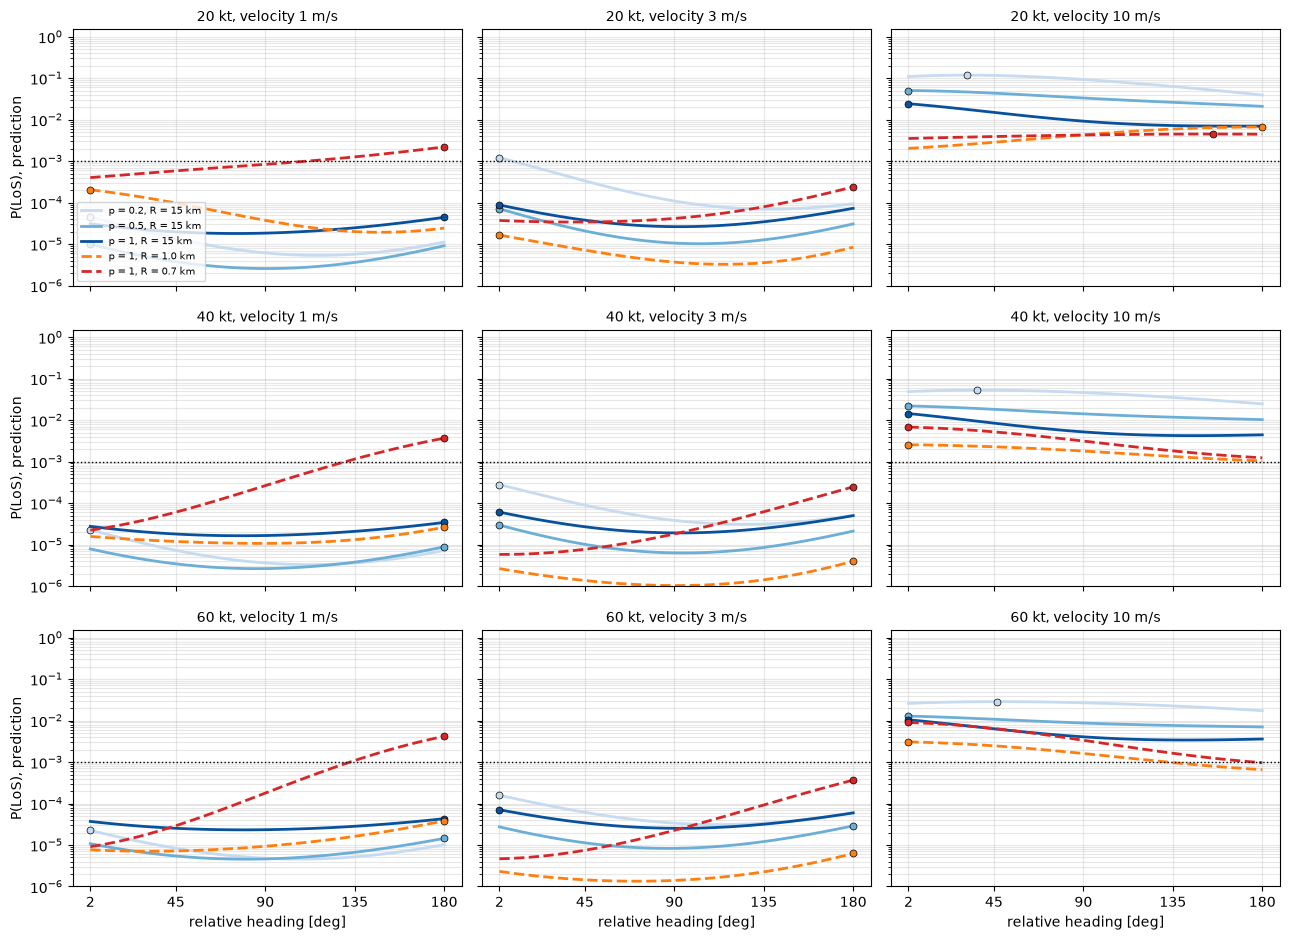

,speed,velocity [m/s],worst at 2 deg,worst at 180 deg,worst in between
0,20 kt,1.0,0.71,0.29,0.00
1,20 kt,3.0,0.73,0.20,0.08
2,20 kt,10.0,0.10,0.05,0.85
3,40 kt,1.0,0.47,0.49,0.05
4,40 kt,3.0,0.53,0.39,0.08
5,40 kt,10.0,0.32,0.05,0.63
6,60 kt,1.0,0.36,0.56,0.08
7,60 kt,3.0,0.42,0.48,0.10
8,60 kt,10.0,0.41,0.04,0.55


In [3]:
# P(LoS) against relative heading (prediction), position accuracy 10 m.
POS = 1
ip = lambda v: int(np.argmin(np.abs(phys["p_reception"] - v)))
ir = lambda km: int(np.argmin(np.abs(phys["max_range_m"] / 1e3 - km)))
CURVES = [(f"p = {v:g}, R = 15 km", ip(v), N_R - 1, c, "-") for v, c in ((0.2, "#c6dbef"), (0.5, "#6baed6"), (1.0, "#08519c"))] + \
         [(f"p = 1, R = {phys['max_range_m'][ir(km)] / 1e3:.1f} km", N_P - 1, ir(km), c, "--")
          for km, c in ((1.0, "tab:orange"), (0.5, "tab:red"))]
fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharex=True, sharey=True)
worst = []
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        for label, a, b, color, ls in CURVES:
            p = 10 ** MU[POS, j, k][a, b, :]
            ax.plot(phys["dpsi"], p, color=color, ls=ls, lw=2, label=label)
            iw = int(np.argmax(p)); ax.plot(phys["dpsi"][iw], p[iw], "o", color=color, ms=5, mec="k", mew=0.5)
        ax.axhline(1e-3, color="k", lw=1, ls=":"); ax.set_yscale("log"); ax.set_ylim(1e-6, 1.5)
        ax.set_xticks([2, 45, 90, 135, 180]); ax.grid(alpha=0.3, which="both")
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s", fontsize=10)
        if k == 2: ax.set_xlabel("relative heading [deg]")
        if j == 0: ax.set_ylabel("P(LoS), prediction")
axes[0, 0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig("results/R_plos_vs_heading.png", dpi=130); plt.show()

# Where the worst heading lies, over the whole (reception, range) grid, per class (all positions).
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        iw = np.concatenate([MU[i, j, k].argmax(-1).ravel() for i in range(4)])
        worst.append({"speed": kt(spd), "velocity [m/s]": vel,
                      "worst at 2 deg": np.mean(iw == 0), "worst at 180 deg": np.mean(iw == N_PSI - 1),
                      "worst in between": np.mean((iw > 0) & (iw < N_PSI - 1))})
display(pd.DataFrame(worst).round(2))

## 5.3 The requirement

The requirement is set by Exp. 2, at the two worst headings (Fig. R5). Each regime constrains a different CNS variable.

**Shallow encounters (2°, 20 kt) set a reception floor; the surveillance range has no effect.**
- **3 m/s velocity accuracy:** every boundary is a line of constant reception probability, about 0.61–0.62 (3 and 10 m position accuracy) and 0.56 (30 m). With 92.6 m position accuracy no reception probability is enough.
- **1 m/s:** almost the whole plane is acceptable.

In a slow, near-parallel conflict the intruder stays within range for minutes, so how far out it is first detected does not matter. Reception does: the conflict lasts long enough for missed messages to accumulate.

**Head-on encounters (180°, 60 kt) set a range floor.**
- **Range:** about 0.8–1 km at reception probability 1, rising to about 3 km at low reception.
- **Reception:** at 3 m/s there is also a floor, but only about 0.13–0.16.
- **Position accuracy:** no effect in this regime.

At twice the cruise speed of closure, detection must happen early enough to resolve.

**Velocity accuracy decides in both regimes.** 10 m/s is never acceptable.
- **At 2°:** it misses by orders of magnitude.
- **At 180°:** it misses narrowly, by a factor of 2–5.

**A CNS system must meet both:** a reception probability of about 0.6 or better, from the shallow regime, and a surveillance range of about 1 km or more, from the head-on regime, with velocity accuracy of 3 m/s or better and position accuracy better than 92.6 m at 3 m/s (Table R1). Both boundaries are resolved: the max straddle fell below zero in both runs, and the independent check of Section 5.6 confirms their position.

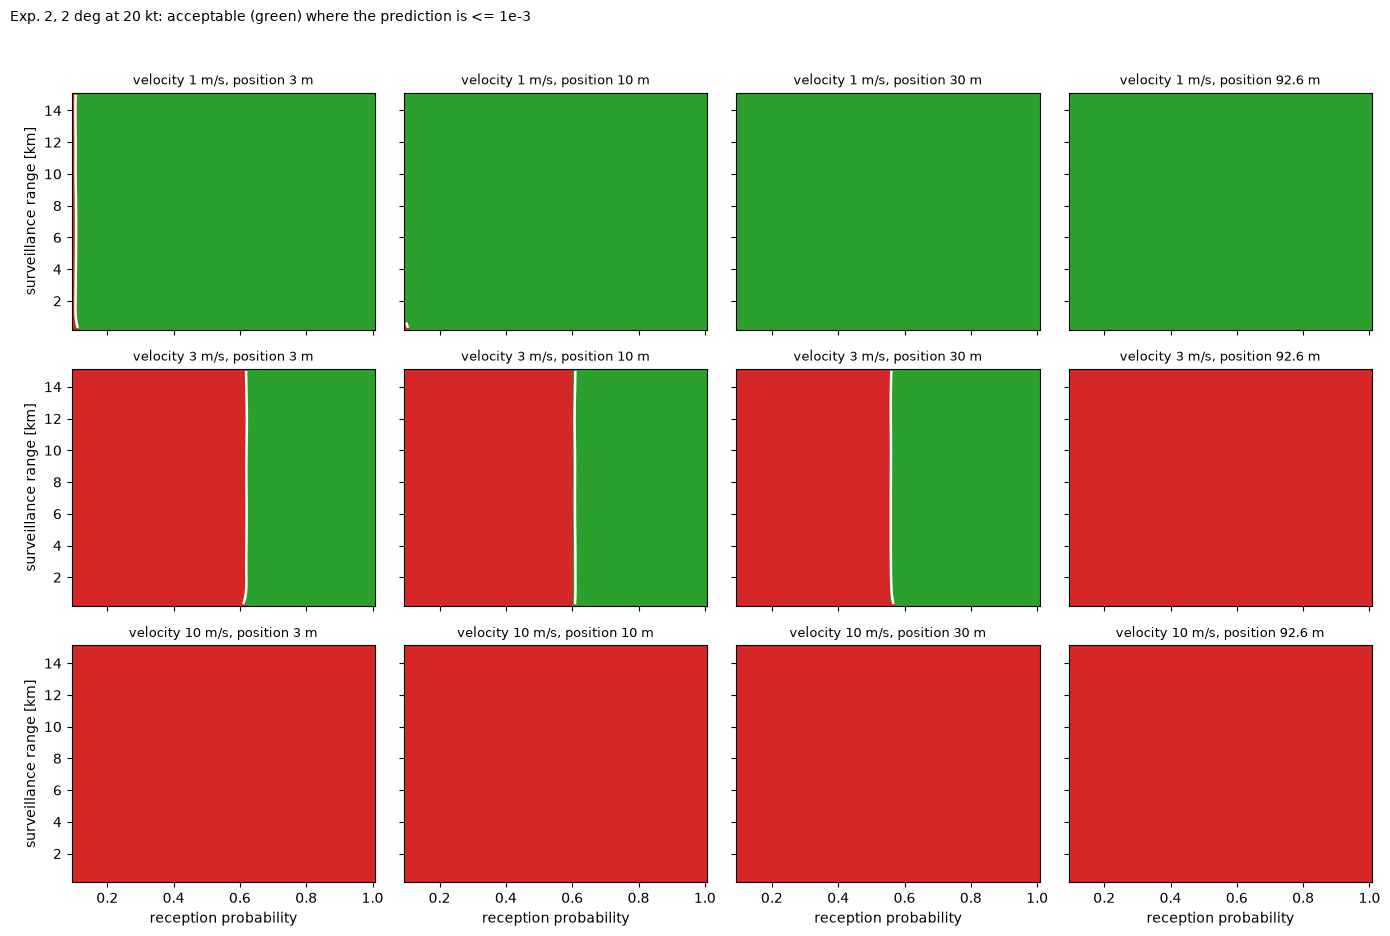

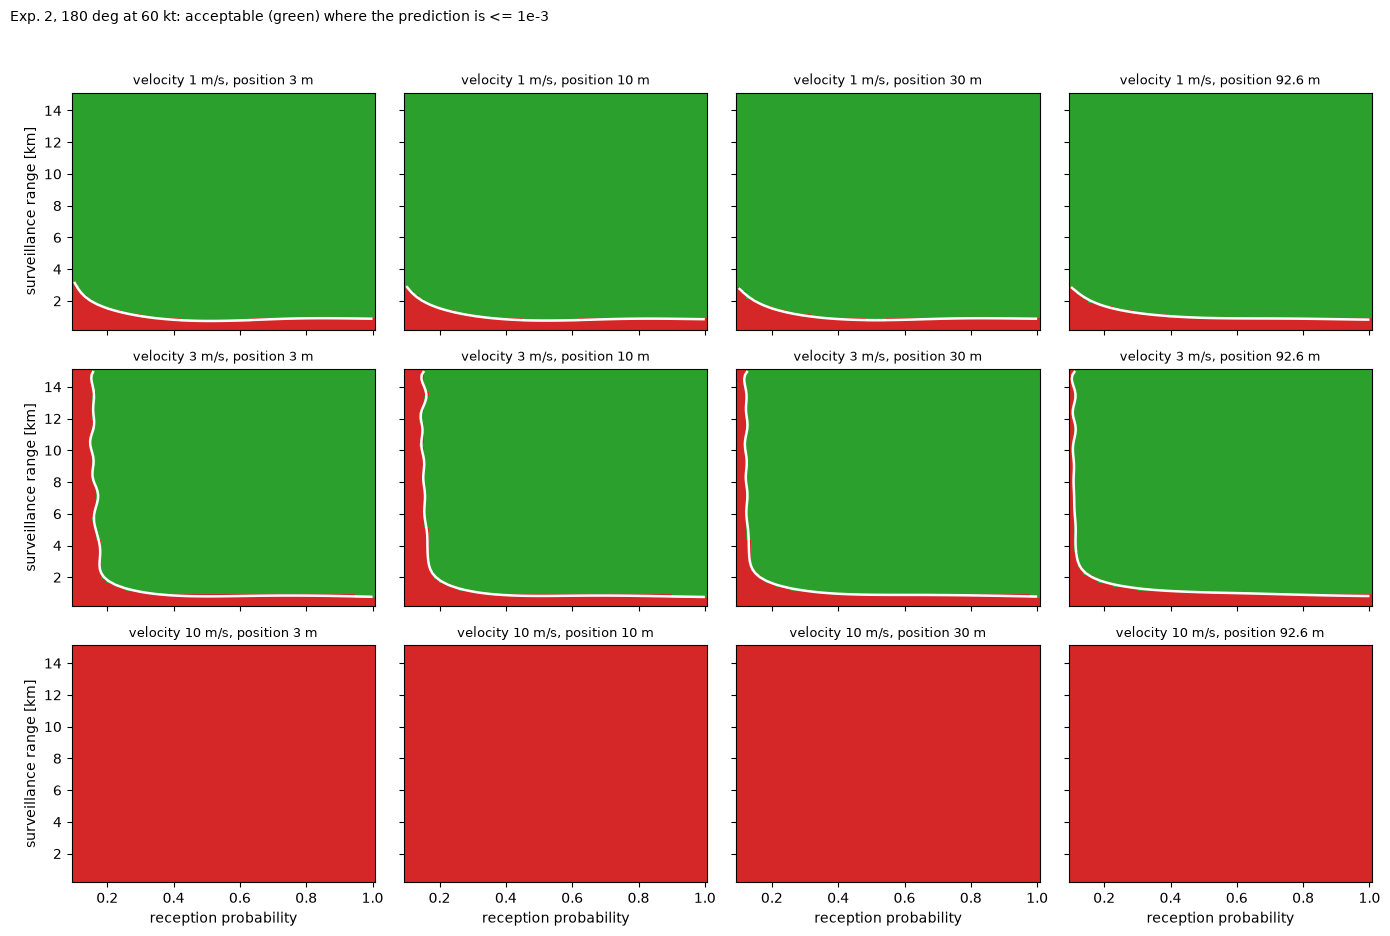

,velocity [m/s],position [m],shallow: min reception (any range > 1 km),head-on: min range at reception 1 [km],head-on: min reception at 15 km
0,1.0,3.0,0.12,1.0,0.10
1,1.0,10.0,0.10,1.0,0.10
2,1.0,30.0,0.10,1.0,0.10
3,1.0,92.6,0.10,1.0,0.10
4,3.0,3.0,0.62,0.8,0.16
5,3.0,10.0,0.61,0.8,0.16
6,3.0,30.0,0.56,0.8,0.13
7,3.0,92.6,none,1.0,0.12
8,10.0,3.0,none,none,none
9,10.0,10.0,none,none,none


In [4]:

# Exp. 2: acceptable (green) where the prediction is <= 1e-3; rows velocity, columns position accuracy.
N2 = 61
gp_, gr_ = np.meshgrid(np.linspace(0, 1, N2), np.linspace(0, 1, N2), indexing="ij")
base2 = np.column_stack([gp_.ravel(), gr_.ravel()])
P2_, R2_ = space2.variable("p_reception").from_unit(gp_), space2.variable("max_range_m").from_unit(gr_) / 1e3
lv = {n: space2.variable(n).levels for n in space2.discrete_names}
MU2 = {}
for d, v in EXP2.items():
    fig, axes = plt.subplots(3, 4, figsize=(14, 9.5), sharex=True, sharey=True)
    for j, vel in enumerate(lv["vel_ci95"]):
        for i, pos in enumerate(lv["pos_ci95"]):
            mu = v["model"].predict(np.column_stack([base2, np.full(len(base2), i), np.full(len(base2), j)]))[0].reshape(N2, N2)
            MU2[d, i, j] = mu
            ax = axes[j, i]
            ax.pcolormesh(P2_, R2_, (mu <= TAU).astype(float), cmap=TWO, vmin=0, vmax=1, shading="auto")
            ax.contour(P2_, R2_, mu, levels=[TAU], colors="white", linewidths=1.8, linestyles="solid")
            ax.set_title(f"velocity {vel:g} m/s, position {pos:g} m", fontsize=9)
            if j == 2: ax.set_xlabel("reception probability")
            if i == 0: ax.set_ylabel("surveillance range [km]")
    fig.suptitle(f"Exp. 2, {d:.0f} deg at {kt(v['speed'])}: acceptable (green) where the prediction is <= 1e-3",
                 x=0.01, ha="left", fontsize=10)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.savefig(f"results/R_exp2_{d:.0f}deg.png", dpi=130); plt.show()

# Table R1: the requirement per accuracy class. Shallow: lowest reception probability acceptable at every range
# above 1 km. Head-on: shortest acceptable range at reception probability 1, and lowest acceptable reception
# probability at 15 km. "none": not acceptable anywhere on the plane.
pr, rr = P2_[:, 0], R2_[0, :]
def min_p(mu, ranges):
    ok = (mu[:, ranges] <= TAU).all(axis=1)
    return f"{pr[ok].min():.2f}" if ok.any() else "none"
rows = []
for j, vel in enumerate(lv["vel_ci95"]):
    for i, pos in enumerate(lv["pos_ci95"]):
        m2, m180 = MU2[2.0, i, j], MU2[180.0, i, j]
        r_ok = m180[-1, :] <= TAU
        rows.append({"velocity [m/s]": vel, "position [m]": pos,
                     "shallow: min reception (any range > 1 km)": min_p(m2, rr > 1.0),
                     "head-on: min range at reception 1 [km]": f"{rr[r_ok].min():.1f}" if r_ok.any() else "none",
                     "head-on: min reception at 15 km": min_p(m180, rr >= rr.max())})
table_r1 = pd.DataFrame(rows)
table_r1.to_csv("results/R_requirement_table.csv", index=False)
table_r1


## 5.4 The definition over the heading

The requirement is read as the worst case over the heading. Exp. 1, which spans the headings, shows how much the definition matters. Replacing it with an average over the heading changes the result only at 3 m/s:

| speed class | worst case | uniform average | closing-speed weighted |
|---|---|---|---|
| 20 kt | 0.78 | 0.87 | 0.89 |
| 40 kt | 0.88 | 0.93 | 0.93 |
| 60 kt | 0.89 | 0.92 | 0.93 |

(Acceptable share of the reception–range plane at 3 m/s.)

At 1 and 10 m/s, all three definitions agree. The velocity requirement therefore does not depend on how the heading is weighted. Only the reception and range floors at 3 m/s do.

In [5]:
# The requirement under three definitions over the heading (acceptable share of the reception-range
# plane, prediction, averaged over position classes). Averages are over probabilities.
psi = phys["dpsi"]
WEIGHTS = {"uniform average": np.ones_like(psi) / len(psi),
           "closing-speed weighted": np.sin(np.radians(psi) / 2) / np.sin(np.radians(psi) / 2).sum()}
rows = []
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        r = {"speed": kt(spd), "velocity [m/s]": vel}
        r["worst case"] = np.mean([np.mean(MU[i, j, k].max(-1) <= TAU) for i in range(4)])
        for name, wt in WEIGHTS.items():
            r[name] = np.mean([np.mean(np.log10((10 ** MU[i, j, k] * wt).sum(-1)) <= TAU) for i in range(4)])
        rows.append(r)
pd.DataFrame(rows).round(2)

,speed,velocity [m/s],worst case,uniform average,closing-speed weighted
0,20 kt,1.0,0.97,0.97,0.97
1,20 kt,3.0,0.78,0.87,0.89
2,20 kt,10.0,0.00,0.00,0.00
3,40 kt,1.0,0.95,0.96,0.96
4,40 kt,3.0,0.88,0.93,0.93
5,40 kt,10.0,0.00,0.00,0.00
6,60 kt,1.0,0.93,0.95,0.95
7,60 kt,3.0,0.89,0.93,0.92
8,60 kt,10.0,0.00,0.00,0.00


## 5.5 Correlations between levels

The hypersphere decomposition estimates one correlation matrix per discrete variable (Fig. R3). Exp. 2, with about 20 samples per category, gives the clearer picture.

- **Velocity accuracy:** at 2°, the 10 m/s level is negatively correlated with 1 m/s (−0.70; −0.27 in Exp. 1). At 180°, where 10 m/s fails only narrowly, the two are nearly uncorrelated (−0.09). The coarsest class does not behave as more of the same error. A correlation function that cannot represent a negative correlation between levels can at best treat these two as uncorrelated (Section 4.2). The data themselves are therefore the case for the hypersphere decomposition.
- **Position accuracy:** the levels are correlated at 0.89–0.99. That explains why the requirement barely depends on position accuracy, except for its coarsest class at 3 m/s and 2° (Section 5.3).
- **Speed class (Exp. 1):** 40 and 60 kt, both fixed-wing, correlate at 0.97, and the 20 kt multirotor less (0.72–0.85).

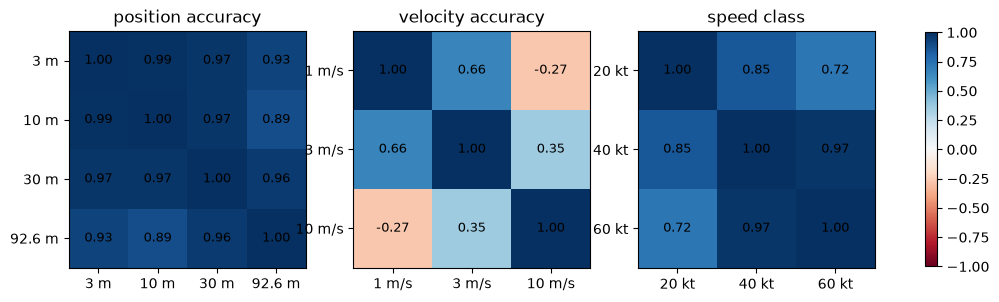

exp2 2 deg: {'pos_ci95': [[1.0, 0.99, 0.99, 0.95], [0.99, 1.0, 0.99, 0.96], [0.99, 0.99, 1.0, 0.98], [0.95, 0.96, 0.98, 1.0]], 'vel_ci95': [[1.0, 0.06, -0.7], [0.06, 1.0, -0.05], [-0.7, -0.05, 1.0]]}
exp2 180 deg: {'pos_ci95': [[1.0, 0.99, 0.98, 0.95], [0.99, 1.0, 0.97, 0.96], [0.98, 0.97, 1.0, 0.98], [0.95, 0.96, 0.98, 1.0]], 'vel_ci95': [[1.0, 0.71, -0.09], [0.71, 1.0, 0.56], [-0.09, 0.56, 1.0]]}


In [6]:
# Correlations between the levels of each discrete variable (hypersphere decomposition).
lc = model.level_correlations()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name, unit in zip(axes, ("pos_ci95", "vel_ci95", "speed"), ("m", "m/s", "")):
    labels = [kt(v) if name == "speed" else f"{v:g} {unit}" for v in levels[name]]
    m = np.asarray(lc[name])
    im = ax.imshow(m, vmin=-1, vmax=1, cmap="RdBu")
    for (a, b), v in np.ndenumerate(m):
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(labels)), labels); ax.set_yticks(range(len(labels)), labels)
    ax.set_title({"pos_ci95": "position accuracy", "vel_ci95": "velocity accuracy", "speed": "speed class"}[name])
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig("results/R_level_correlations.png", dpi=130); plt.show()
for d, v in EXP2.items():
    print(f"exp2 {d:.0f} deg:", {k: np.round(m, 2).tolist() for k, m in v['model'].level_correlations().items()})

## 5.6 Reliability of the fitted boundaries

**(a) The active learning process.** Exp. 1 ended on its limit of 250 samples, not resolved.
- **Max straddle:** it never fell below zero, ending at +1.48.
- **Ambiguous points:** the share of points whose interval contains $10^{-3}$ rose from about 3% to 10–30% as samples revealed the structure of the response.

Both Exp. 2 runs met "max straddle < 0": at 2° after 111 samples (final −0.04, 0.1% ambiguous), and at 180° after 176 (final −0.35, 0.8%). Parts (b) and (c) show what that does and does not establish.

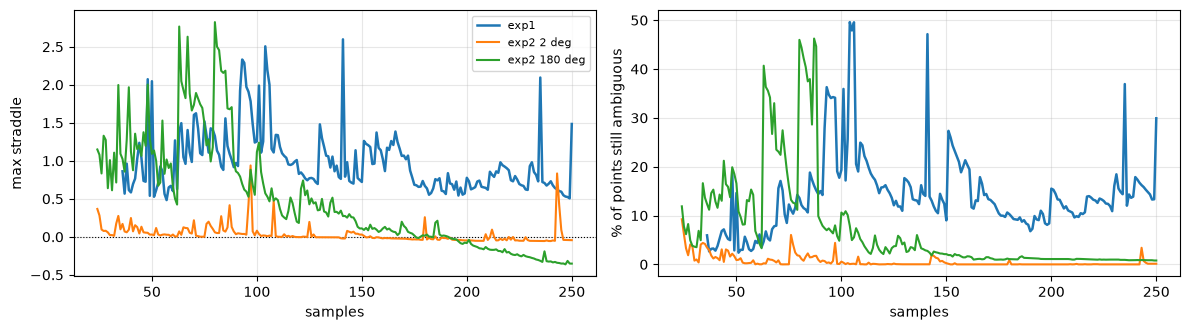

final max straddle +1.48; ambiguous 30%; stop: budget (250 evaluations)


In [7]:
# (a) The active learning process: max straddle and share of points whose interval contains 1e-3.
rounds = pd.DataFrame(run["outcome"]["rounds"])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.4))
a.plot(rounds.n_evaluations, rounds.max_straddle, lw=1.8, label="exp1"); a.axhline(0, color="k", lw=0.8, ls=":")
a.set_xlabel("samples"); a.set_ylabel("max straddle"); a.grid(alpha=0.3)
b.plot(rounds.n_evaluations, 100 * rounds.ambiguous_fraction, lw=1.8, label="exp1")
for k, (d, v) in enumerate(EXP2.items()):
    r2 = pd.DataFrame(v["run"]["outcome"]["rounds"])
    a.plot(r2.n_evaluations, r2.max_straddle, lw=1.5, color=f"C{k + 1}", label=f"exp2 {d:.0f} deg")
    b.plot(r2.n_evaluations, 100 * r2.ambiguous_fraction, lw=1.5, color=f"C{k + 1}", label=f"exp2 {d:.0f} deg")
a.legend(fontsize=8)
b.set_xlabel("samples"); b.set_ylabel("% of points still ambiguous"); b.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/R_convergence.png", dpi=130); plt.show()
print(f"final max straddle {run['outcome']['final_max_straddle']:+.2f}; ambiguous "
      f"{run['outcome']['final_ambiguous_fraction']:.0%}; stop: {run['outcome']['stop_reason']}")

**(b1) Hold-out samples.** 108 unmapped points (3 per category, uniform in reception, range and heading) were simulated with $10^5$ encounters each. Their encounters are independent of the campaign's.

- **Side of $10^{-3}$:** the prediction placed all 108 on the correct side. This says little about the boundary itself: only 2 of them were measured within half a decade of $10^{-3}$, because the response jumps across the threshold rather than crossing it gently.
- **Accuracy:** over the 60 points with LoS, the prediction is typically within a factor of 1.9 of the measured value (median), with an RMS error of 0.46 decades.
- **Uncertainty:** the modelling uncertainty is honest and cautious. Normalised errors $z = (y - \hat y)/\sqrt{s^2 + s_{MC}^2}$ have mean −0.16 and standard deviation 0.70 (ideal 0 and 1), and all 60 points lie inside the 95% interval.
- **No-LoS points:** of the 48 with no LoS, 44 are predicted below the $3/N$ bound, and the other 4 above it, on the safe side.

108 hold-out points, 60 with LoS, 48 without
side of 1e-3 correct: 100%; within 0.5 decade of 1e-3: 2 points
error of the prediction: median factor 1.9, RMS 0.46 decades
z = (measured - prediction) / sqrt(s^2 + se^2): mean -0.16, sd 0.70; inside the 95% interval 100%


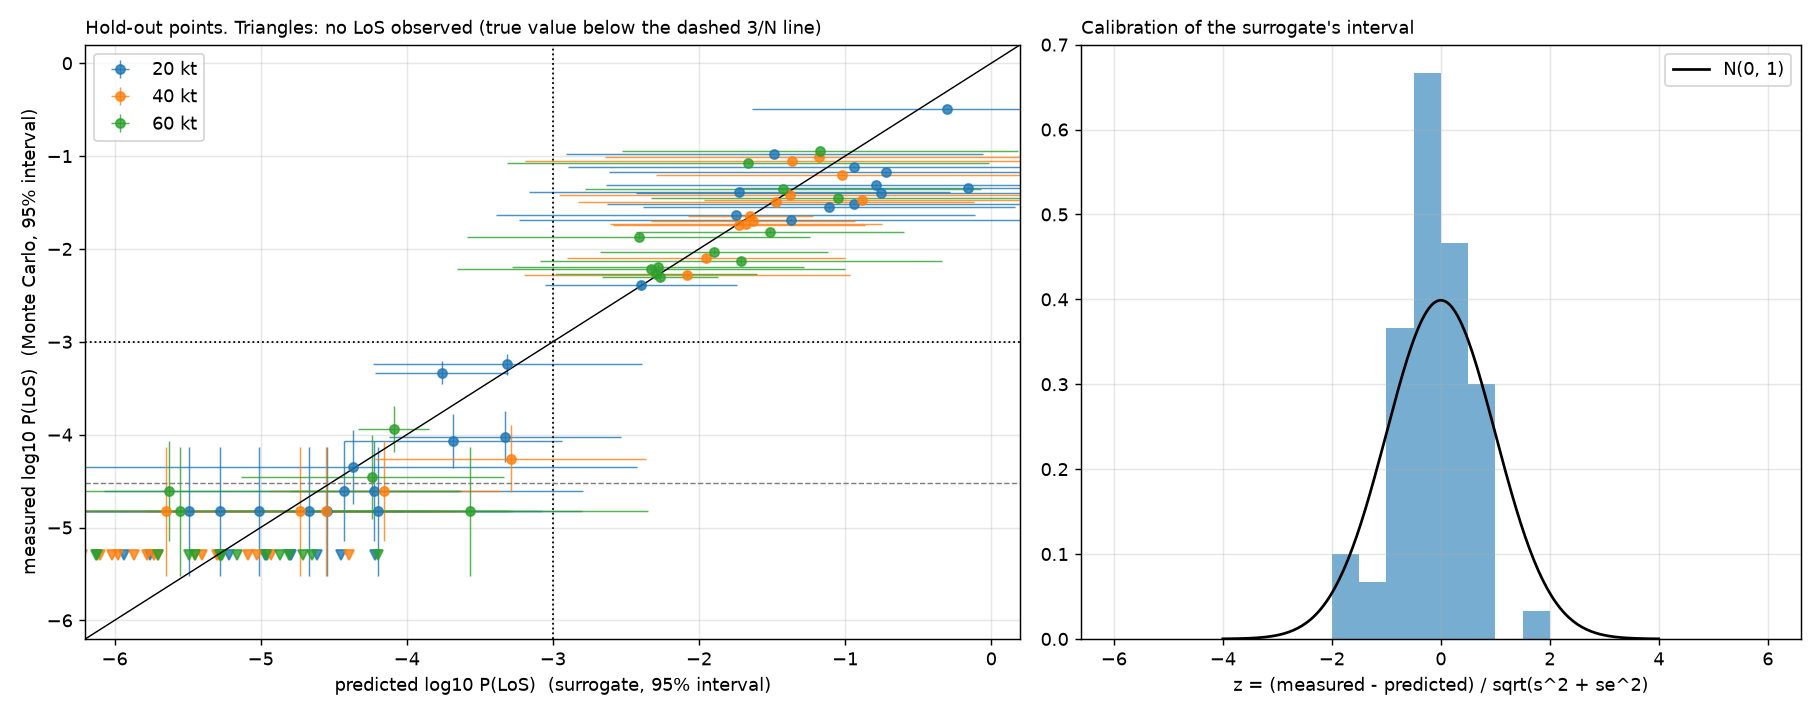

In [8]:
# (b1) Hold-out samples (notebook 15): 108 unmapped points, fresh Monte Carlo on independent encounters.
ho = pd.read_csv("results/exp1_holdout.csv")
nz = ho[~ho.zero]
print(f"{len(ho)} hold-out points, {len(nz)} with LoS, {int(ho.zero.sum())} without")
print(f"side of 1e-3 correct: {ho.class_ok.mean():.0%}; within 0.5 decade of 1e-3: {int(ho.near_tau.sum())} points")
print(f"error of the prediction: median factor {10 ** np.median(np.abs(nz.y - nz.mu)):.1f}, "
      f"RMS {np.sqrt(np.mean((nz.y - nz.mu) ** 2)):.2f} decades")
print(f"z = (measured - prediction) / sqrt(s^2 + se^2): mean {nz.z.mean():+.2f}, sd {nz.z.std():.2f}; "
      f"inside the 95% interval {nz.inside95.mean():.0%}")
from IPython.display import Image
display(Image("results/exp1_holdout.png", width=900))

**(b2) Boundary check of Exp. 1.** 30 designs whose predicted worst case over the heading equals $10^{-3}$ (at most two per category) were simulated with $10^6$ encounters at their predicted worst heading, and with $10^5$ at the other end of the heading range. Their encounters are independent of the campaign's.

**The surrogate model is least accurate where the requirement is decided.**
- **Spread of the measured values:** from no LoS to $3\times10^{-2}$, a median factor of 4 from the prediction.
- **Interval:** only 16 of 30 lie inside the 95% interval. The hold-out showed cautious intervals overall; on the boundary they are overconfident.

**The error is systematic, by heading.**
- **2°:** where 2° was predicted worst, 13 of 14 designs measure above $10^{-3}$ (median factor 3.6, up to 20).
- **180°:** where 180° was predicted worst, 7 of 8 measure below.
- **Wrong end:** in 8 of 30 the other end is clearly worse than the predicted worst heading.

$P(\mathrm{LoS})$ rises towards the shallow end faster than the surrogate model, fitted to the 49 samples between 2° and 20°, can follow.

**A requirement read from Exp. 1 would be too lenient.** 23 of the 30 boundary designs exceed $10^{-3}$ at one of the two ends. This is why the requirement is set by Exp. 2. Exp. 1 locates the worst headings, and its shallow end is the part the surrogate model fitted worst. At 2° and 20 kt, Exp. 1 accepts 0.80–0.85 of the plane at 3 m/s, where Exp. 2 accepts 0.43–0.49 (notebook 18).

,speed_kt,vel,pos,p,R_km,worst dpsi,predicted,measured,meas 95% lo,meas 95% hi,predicted acceptable,measured acceptable,other end measured
0,20,3.0,10.0,0.3700,10.2225,2.00000,0.00100,0.00290,0.00280,0.00301,True,False,0.00001
1,20,3.0,30.0,0.2575,12.7950,2.00000,0.00100,0.00633,0.00617,0.00648,False,False,0.00007
2,40,3.0,3.0,0.1900,13.5300,2.00000,0.00100,0.00362,0.00350,0.00374,True,False,0.00028
3,20,3.0,30.0,0.4600,0.6675,180.00000,0.00100,0.00003,0.00002,0.00004,True,True,0.00160
4,20,3.0,92.6,0.3700,1.0350,2.00000,0.00100,0.00250,0.00240,0.00260,False,False,0.00005
5,40,3.0,30.0,0.1225,5.0775,2.00000,0.00100,0.01334,0.01312,0.01357,False,False,0.00085
6,20,3.0,92.6,0.5275,0.6675,180.00000,0.00100,0.00051,0.00047,0.00056,True,True,0.00142
7,60,3.0,10.0,0.1675,8.3850,66.27778,0.00100,0.00018,0.00015,0.00020,False,True,0.00062
8,20,3.0,10.0,0.5050,10.5900,2.00000,0.00100,0.00136,0.00129,0.00143,False,False,0.00003
9,60,3.0,30.0,0.1675,10.2225,180.00000,0.00100,0.00019,0.00016,0.00022,True,True,0.00037


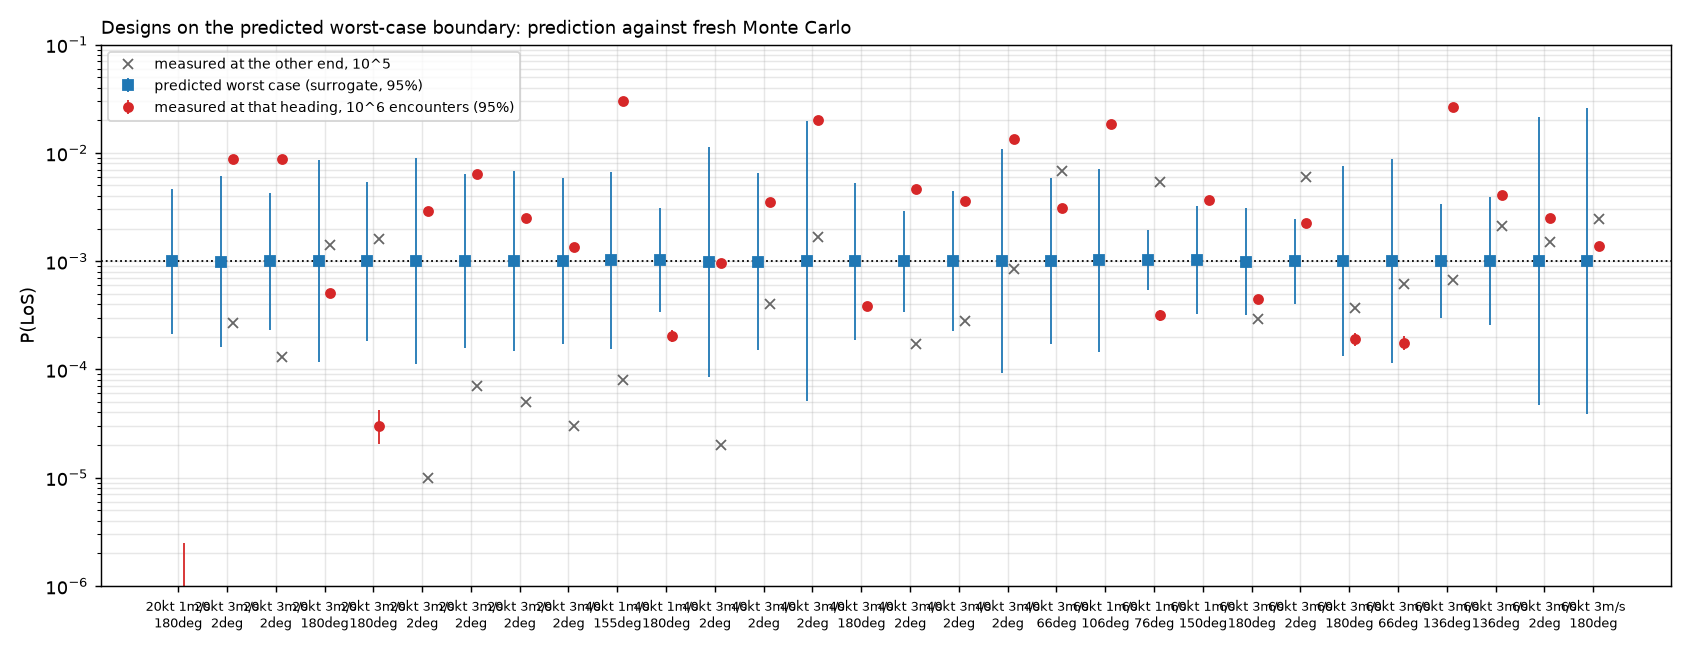

In [9]:
# (b2) Boundary check (notebook 16): designs on the predicted worst-case boundary, 1e6 encounters.
p = Path("results/exp1_boundary_check.csv")
if p.exists() and Path("results/exp1_boundary_check.png").exists():
    bc = pd.read_csv(p)
    display(bc[["speed_kt", "vel", "pos", "p", "R_km", "worst dpsi", "predicted", "measured", "meas 95% lo",
                "meas 95% hi", "predicted acceptable", "measured acceptable", "other end measured"]].round(5))
    display(Image("results/exp1_boundary_check.png", width=900))
else:
    print("notebook 16 has not finished yet")

**(b3) Boundary check of Exp. 2.** On each surface, the 30 points whose prediction is closest to $10^{-3}$ (at most 3 per category) were simulated again with $10^6$ encounters, independent of the campaign's. At 2°, points that differ only in range gave identical encounters, which leaves 20 independent points.

**The boundaries are in the right place and unbiased.**
- **Median measured/predicted:** 0.98 at 2° and 1.03 at 180°.
- **Above $10^{-3}$:** 8 of 20 and 16 of 30 points.
- **Typical error at 1 and 3 m/s:** a factor of 1.07 and 1.18.

That is about the Monte Carlo precision of $10^5$ encounters at $10^{-3}$ (a 95% interval of about ±20%). The bias that Exp. 1 had at 2° is gone.

**The modelling uncertainty is far too small.** Only 15% (2°) and 43% (180°) of the measured values lie inside the 95% interval. At 2° the interval is almost zero (0.004 decades), while the campaign's own Monte Carlo error at $10^{-3}$ is 0.043 decades.
- **Why the surrogate cannot see this error:** it interpolates responses treated as exact, and every response comes from the same $10^5$ encounters, so their errors are correlated.
- **The fix for reporting:** adding $s_{MC}$ to the modelling uncertainty raises coverage to 80% and 71% at 1 and 3 m/s. Requirement boundaries are therefore quoted with $\sqrt{s^2 + s_{MC}^2}$.

Where samples were sparse (10 m/s), the predicted size is wrong, by up to a factor of 50 at 2°, but every design stays on the correct side of $10^{-3}$.

,independent points,measured / predicted (median),above 1e-3,inside 95% interval,"inside, with MC error (1, 3 m/s)",median s [decades]
heading,,,,,,
2 deg,20,0.98,8/20,15%,80%,0.004
180 deg,30,1.03,16/30,43%,71%,0.052


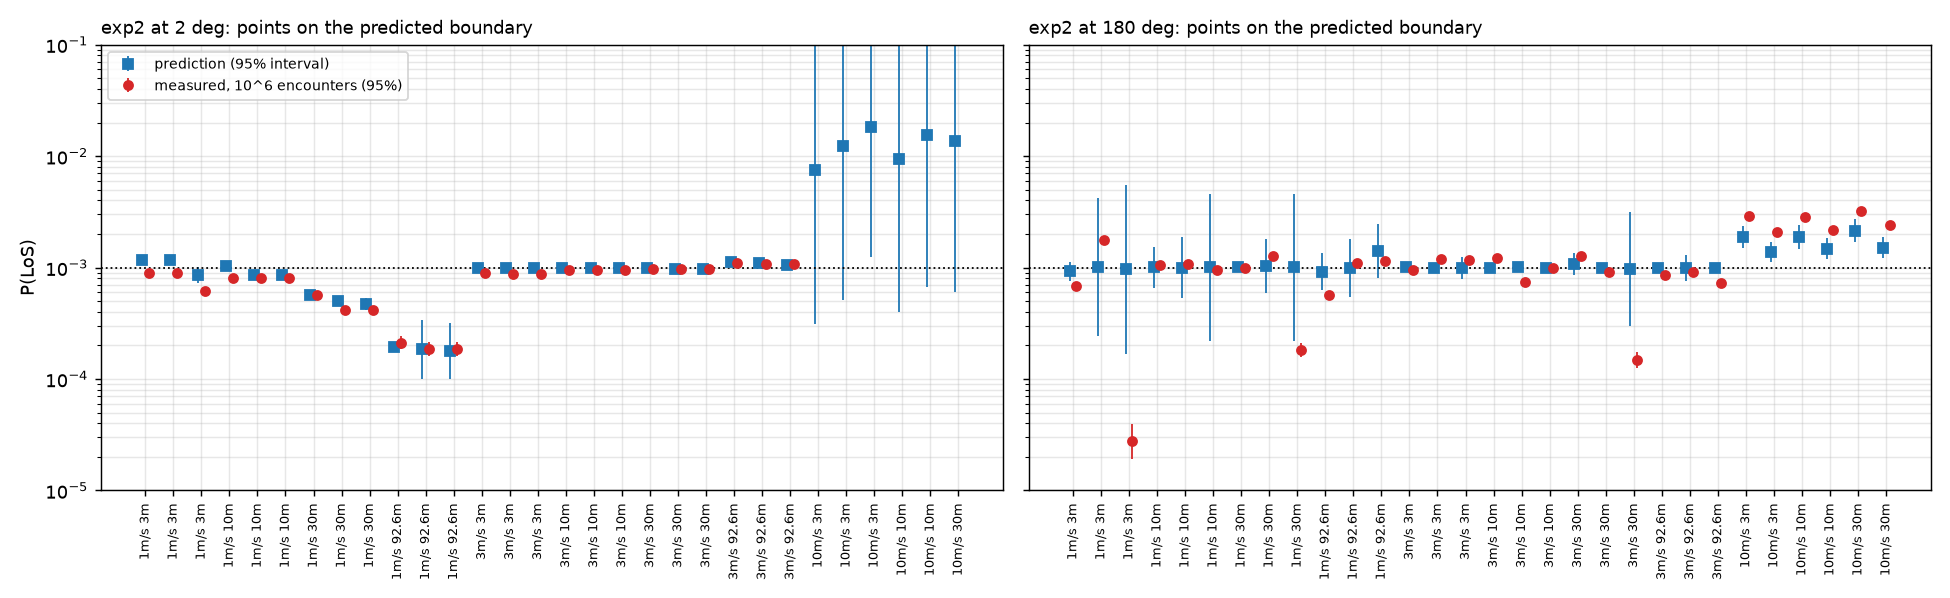

In [10]:

bc2 = pd.read_csv("results/exp2_boundary_check.csv")
out = []
for h, g in bc2.groupby("heading", sort=False):
    g = g.drop_duplicates(subset=["vel", "pos", "p", "measured"])        # identical encounters count once
    mu, s = np.log10(g.predicted), np.log10(g["pred 95% hi"] / g.predicted) / 1.96
    se = np.sqrt((1 - g.predicted) / (N * g.predicted)) / np.log(10)
    meas = np.log10(g.measured.clip(lower=1e-7))
    inside_tot = np.abs(meas - mu) <= 1.96 * np.sqrt(s ** 2 + se ** 2)
    acc = g.vel < 10
    out.append({"heading": h, "independent points": len(g), "measured / predicted (median)": round(float(np.nanmedian(g.factor)), 2),
                "above 1e-3": f"{int(g['measured above 1e-3'].sum())}/{len(g)}",
                "inside 95% interval": f"{g['inside pred 95%'].mean():.0%}",
                "inside, with MC error (1, 3 m/s)": f"{inside_tot[acc].mean():.0%}",
                "median s [decades]": round(float(s.median()), 3)})
display(pd.DataFrame(out).set_index("heading"))
display(Image("results/exp2_boundary_check.png", width=950))


**(c) What "max straddle < 0" is worth.** The analytical test-cases of Section 4.6 were rerun with Monte Carlo responses at $10^5$ encounters, treated as exact, as in the campaigns. Each run continued to 250 samples, and the classification was scored where the rule would have stopped it.

| responses | rule fires (Goldstein, 20 runs) | F1 when it fires | confidently safe but truly unsafe |
|---|---|---|---|
| exact | 20 | ≥ 0.998 | ≈ 0 |
| Monte Carlo, independent encounters | 0 | — | — |
| Monte Carlo, common random numbers (as the campaigns) | 9 | 0.988–0.996 | up to 1.1% of the domain |

With common random numbers, the noisy response stays smooth, so the surrogate model interpolates it and becomes confident about the encounter set rather than about the true $P(\mathrm{LoS})$. This is the mechanism behind (b3). The rule can also fire falsely right after the initial samples, before any sample has found the structure (one Himmelblau run, F1 = 0). "Max straddle < 0" is therefore reported, but not as evidence of convergence. The evidence is the independent check (b3).

In [11]:

s20 = pd.read_csv("results/exp0d_stop_rule.csv"); s21 = pd.read_csv("results/exp0e_stop_rule_crn.csv")
display(pd.concat({"independent encounters": s20.set_index("problem"), "common random numbers": s21.set_index("problem")}))


rule fires at sample  \
                       problem                                    
independent encounters goldstein36_graded        0/10         -   
                       goldstein36_flip          0/10         -   
                       himmelblau36_graded       1/10        36   
common random numbers  goldstein36_graded        3/10       234   
                       goldstein36_flip          6/10       206   
                       himmelblau36_graded       1/10        36   

                                           F1 when it fires (mean, min)  \
                       problem                                            
independent encounters goldstein36_graded                             -   
                       goldstein36_flip                               -   
                       himmelblau36_graded               0.0000, 0.0000   
common random numbers  goldstein36_graded                0.9912, 0.9875   
                       goldstein36_flip                  0.9932, 0.9877   
                       himmelblau36_graded               0.0000, 0.0000   

                                           misclassified when it fires  \
                       problem                                           
independent encounters goldstein36_graded                            -   
                       goldstein36_flip                              -   
                       himmelblau36_graded                       5.54%   
common random numbers  goldstein36_graded                        0.97%   
                       goldstein36_flip                          0.75%   
                       himmelblau36_graded                       5.54%   

                                           confidently safe but truly unsafe  \
                       problem                                                 
independent encounters goldstein36_graded                                  -   
                       goldstein36_flip                                    -   
                       himmelblau36_graded                            0.000%   
common random numbers  goldstein36_graded                             0.494%   
                       goldstein36_flip                               0.326%   
                       himmelblau36_graded                            0.000%   

                                           F1 >= 0.99 first at  F1 at 250  
                       problem                                             
independent encounters goldstein36_graded                  120     0.9926  
                       goldstein36_flip                     98     0.9923  
                       himmelblau36_graded               never     0.6833  
common random numbers  goldstein36_graded                  110     0.9936  
                       goldstein36_flip                     87     0.9942  
                       himmelblau36_graded               never     0.7192

## 5.7 Robustness: the noise model

**What passing the standard error would change (Exp. 1).** The surrogate model is refitted to the same 250 campaign samples, now with each sample's Monte Carlo standard error as known observation noise: $s_{MC}^2$ is added to the diagonal of the correlation matrix, and the delta-method value on the log scale gives about 0.6 decades for a sample with no LoS. Nothing else changes. The boundary-check samples are not used, so they still test both models independently.

**Passing the standard error barely changes the requirement.** The prediction-based acceptable shares move by at most 0.02, and both boundaries lie within the same band at 3 m/s. The boundary error of Section 5.6 (b2) is therefore not caused by treating the responses as exact.
- **Standard error near $10^{-3}$:** 0.046 decades, a small fraction of the factor-of-4 error at the boundary.
- **Boundary check:** both models fail it alike, with a median error of a factor of 3.8 (exact) and 4.1 (with the standard error), and 60% of designs on the correct side for both.

**What changes is the conservative reading.** With the standard error, the re-estimated hyperparameters give a smaller modelling uncertainty, so the share acceptable at the prediction + 1.96 s rises, for example from 0.05–0.13 to 0.12–0.51 at 20 kt and 3 m/s.

That narrower interval is less honest on the boundary: it contains the measured value at 37% of the boundary-check designs, against 50% without the standard error. Treating the responses as exact is thus the more cautious choice here.

standard error per sample: median 0.04 decades; near 1e-3: 0.046; no LoS: 0.61


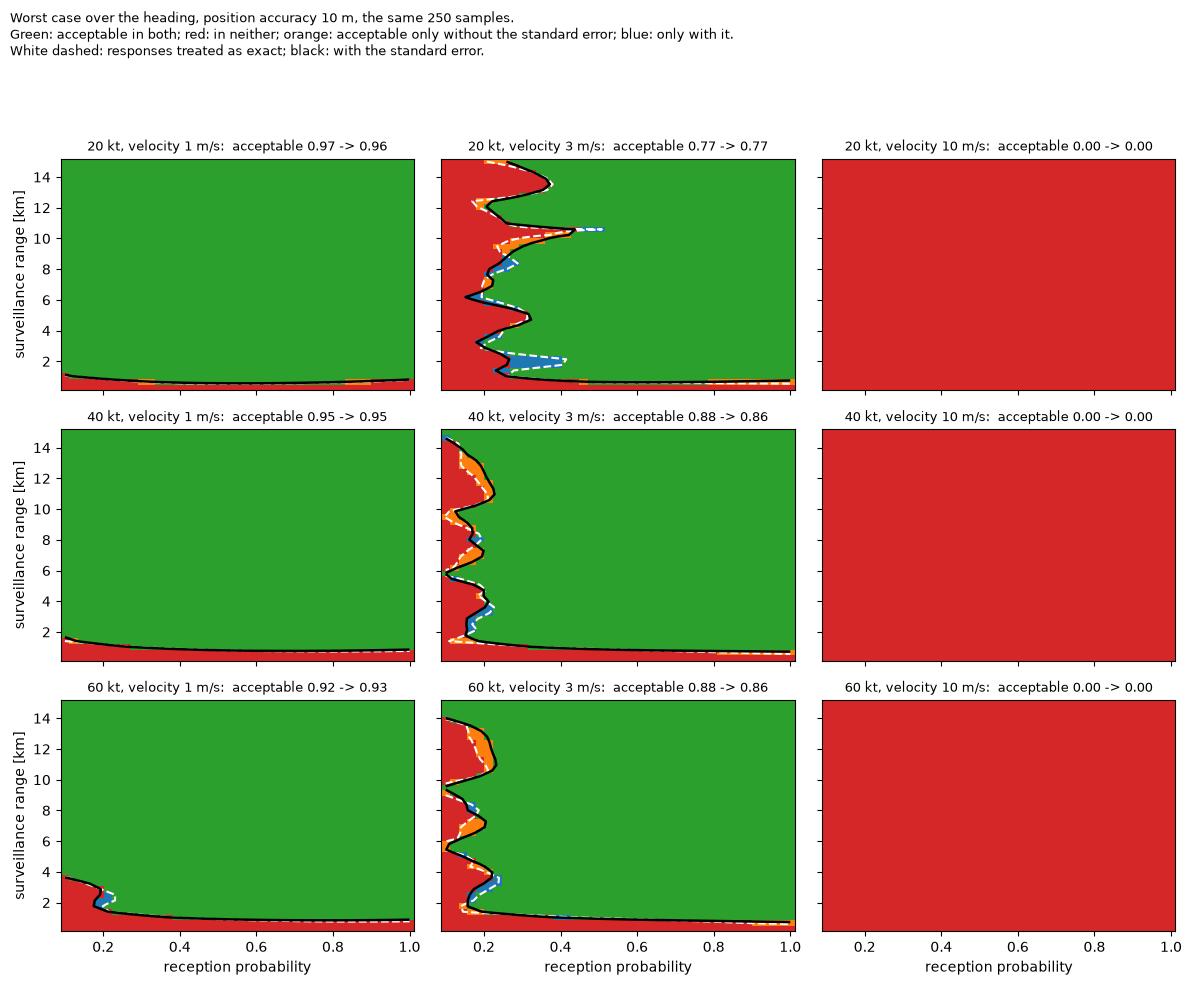

exact       with se       exact, + 1.96 s        \
                       min   max     min   max             min   max   
speed velocity [m/s]                                                   
20 kt 1.0             0.97  0.97    0.95  0.96            0.22  0.43   
      3.0             0.76  0.81    0.75  0.80            0.05  0.13   
      10.0            0.00  0.00    0.00  0.00            0.00  0.00   
40 kt 1.0             0.94  0.95    0.94  0.95            0.42  0.61   
      3.0             0.86  0.91    0.85  0.89            0.30  0.47   
      10.0            0.00  0.00    0.00  0.00            0.00  0.00   
60 kt 1.0             0.92  0.94    0.93  0.94            0.34  0.48   
      3.0             0.87  0.91    0.85  0.89            0.26  0.42   
      10.0            0.00  0.00    0.00  0.00            0.00  0.00   

                     with se, + 1.96 s        
                                   min   max  
speed velocity [m/s]                          
20 kt 1.0                         0.37  0.71  
      3.0                         0.12  0.51  
      10.0                        0.00  0.00  
40 kt 1.0                         0.63  0.87  
      3.0                         0.45  0.78  
      10.0                        0.00  0.00  
60 kt 1.0                         0.52  0.78  
      3.0                         0.40  0.74  
      10.0                        0.00  0.00

,exact,with se
median |error| [factor],3.84,4.13
side of 1e-3 correct,0.60,0.60
inside 95% interval,0.50,0.37
"predicted acceptable, measured not",10.00,8.00


In [12]:
# Same 250 samples, with and without the Monte Carlo standard error of each response.
POS = 1                                                              # position accuracy 10 m
PR, RR = np.meshgrid(phys["p_reception"], phys["max_range_m"] / 1e3, indexing="ij")
FOUR = ListedColormap(["tab:red", "tab:orange", "tab:blue", "tab:green"])
p_hat = 10 ** y
se_mc = np.sqrt((1.0 - p_hat) / (N * p_hat)) / np.log(10.0)          # delta method, as blueskycdarr reports it
model_se = fit_surrogate(config.LSE["method"], space, w, y, se_mc, correlation=config.LSE["correlation"],
                         rng=np.random.default_rng(config.SEED), n_starts=12)
MU3, S3 = {}, {}
for cat in space.categories:
    m, s = model_se.predict(np.column_stack([G, np.tile(np.array(cat, float), (len(G), 1))]))
    MU3[cat], S3[cat] = m.reshape(N_P, N_R, N_PSI), s.reshape(N_P, N_R, N_PSI)
print(f"standard error per sample: median {np.median(se_mc):.2f} decades; near 1e-3: "
      f"{np.median(se_mc[np.abs(y - TAU) < 0.5]):.3f}; no LoS: {se_mc[y <= np.log10(0.5 / (N + 1)) + 1e-9].mean():.2f}")

fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True)
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        before = MU[POS, j, k].max(-1) <= TAU
        after = MU3[POS, j, k].max(-1) <= TAU
        code_ = np.where(before & after, 3, np.where(~before & ~after, 0, np.where(before, 1, 2)))
        ax.pcolormesh(PR, RR, code_, cmap=FOUR, vmin=-0.5, vmax=3.5, shading="auto")
        ax.contour(PR, RR, MU[POS, j, k].max(-1), levels=[TAU], colors="white", linewidths=1.5, linestyles="dashed")
        ax.contour(PR, RR, MU3[POS, j, k].max(-1), levels=[TAU], colors="black", linewidths=1.8, linestyles="solid")
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s:  acceptable {before.mean():.2f} -> {after.mean():.2f}", fontsize=9)
        if k == 2: ax.set_xlabel("reception probability")
        if j == 0: ax.set_ylabel("surveillance range [km]")
fig.suptitle("Worst case over the heading, position accuracy 10 m, the same 250 samples.\n"
             "Green: acceptable in both; red: in neither; orange: acceptable only without the standard error; "
             "blue: only with it.\nWhite dashed: responses treated as exact; black: with the standard error.",
             x=0.01, ha="left", fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.savefig("results/R_requirement_maps_se.png", dpi=130); plt.show()

rows = []
for (ipos, ivel, k), mu in MU.items():
    rows.append({"speed": kt(levels["speed"][k]), "velocity [m/s]": levels["vel_ci95"][ivel],
                 "exact": np.mean(mu.max(-1) <= TAU), "with se": np.mean(MU3[ipos, ivel, k].max(-1) <= TAU),
                 "exact, + 1.96 s": np.mean((mu + 1.96 * S[ipos, ivel, k]).max(-1) <= TAU),
                 "with se, + 1.96 s": np.mean((MU3[ipos, ivel, k] + 1.96 * S3[ipos, ivel, k]).max(-1) <= TAU)})
display(pd.DataFrame(rows).groupby(["speed", "velocity [m/s]"]).agg(["min", "max"]).round(2))

# Both models against the boundary check (independent of both): predicted worst case over the heading at each
# of the 30 designs, against the worse of the two measured ends.
bc = pd.read_csv("results/exp1_boundary_check.csv")
worst_pts = [json.loads(l)["point"] for l in Path("results/exp1_boundary_worst.jsonl").read_text().splitlines() if l.strip()]
wd = space.encode(worst_pts)
meas = np.log10(np.maximum(bc.measured, bc["other end measured"]).clip(lower=1e-7))
out = {}
for name, m in (("exact", model), ("with se", model_se)):
    pred = np.max([m.predict(np.column_stack([wd[:, :2], np.full(len(wd), u), wd[:, 3:]]))[0] for u in su], axis=0)
    mu_s = [m.predict(np.column_stack([wd[:, :2], np.full(len(wd), u), wd[:, 3:]])) for u in su]
    iw = np.argmax([a for a, _ in mu_s], axis=0)
    sd = np.array([mu_s[i][1][d] for d, i in enumerate(iw)])
    out[name] = {"median |error| [factor]": 10 ** np.median(np.abs(meas - pred)),
                 "side of 1e-3 correct": np.mean((pred <= TAU) == (meas <= TAU)),
                 "inside 95% interval": np.mean(np.abs(meas - pred) <= 1.96 * sd),
                 "predicted acceptable, measured not": int(np.sum((pred <= TAU) & (meas > TAU)))}
pd.DataFrame(out).round(2)

## Pending

- **Exp. 3:** the mechanism check of the resolution margin. Not run.
- **Second simulation engine:** the cross-engine check (5.6). Not run.
- **Speed classes at 2°:** Exp. 2 covers 2° at 20 kt only. That 20 kt is the hardest shallow case comes from Exp. 1's shallow end, the part it fitted worst. Exp. 2 at 2° for 40 and 60 kt would check it.
- **Trade-off curves:** from the Exp. 2 surfaces. At 2° the boundaries are vertical, so reception and range do not trade off there; at 180° they do (range against reception at low reception).
- **Outline corrections:** the outline expects a non-monotone correlation for *position* accuracy. The data show it for *velocity* accuracy (−0.70 between 1 and 10 m/s at 2°).